# 7. Live: 2026 week 8 projections

The weekly model from notebook 5 (ridge with snaps and injury reports), used for real.

1. **Backtest on 2026 so far**: train on 2021-2025 only and score weeks 4-7 of 2026, which it has never seen.
2. **Project week 8.** To refresh after Friday's injury reports or for later weeks, run
   `python scripts/project_week.py` (it picks the next unplayed week).

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fantasy.features import TARGET, model_sample
from fantasy.evaluate import score_table, pairwise_accuracy
from fantasy import plots as P

P.use_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
from fantasy.weekly import fit, prepare, project_week, weekly_frame

In [2]:
SEASON, WEEK = 2026, 8
df = weekly_frame(range(2020, 2027), upcoming=(SEASON, WEEK))
played = prepare(model_sample(df[(df.season.between(2021, 2026)) & ~((df.season == SEASON) & (df.week == WEEK))]))
model = fit(played[played.season <= 2025])
season = played[played.season == SEASON].copy()
season["model"] = model.predict(season[[c for c in model[0].feature_names_in_]])
def week_scores(d):
    return {"player-games": len(d),
            "MAE model": (d.model - d[TARGET]).abs().mean(),
            "MAE season avg": (d.avg_season - d[TARGET]).abs().mean(),
            "start/sit model": pairwise_accuracy(d, "model", TARGET),
            "start/sit season avg": pairwise_accuracy(d, "avg_season", TARGET)}

by_week = pd.DataFrame({w: week_scores(d) for w, d in season.groupby("week")}).T
by_week.loc["All"] = week_scores(season)
by_week.round(3)

,player-games,MAE model,MAE season avg,start/sit model,start/sit season avg
4,152.0,5.902,6.654,0.608,0.564
5,158.0,6.218,6.749,0.645,0.621
6,162.0,5.337,5.707,0.667,0.640
7,168.0,5.304,5.764,0.705,0.660
All,640.0,5.680,6.204,0.658,0.623


PosixPath('/home/user/nfl-historic-analysis/reports/figures/16_2026_backtest.png')

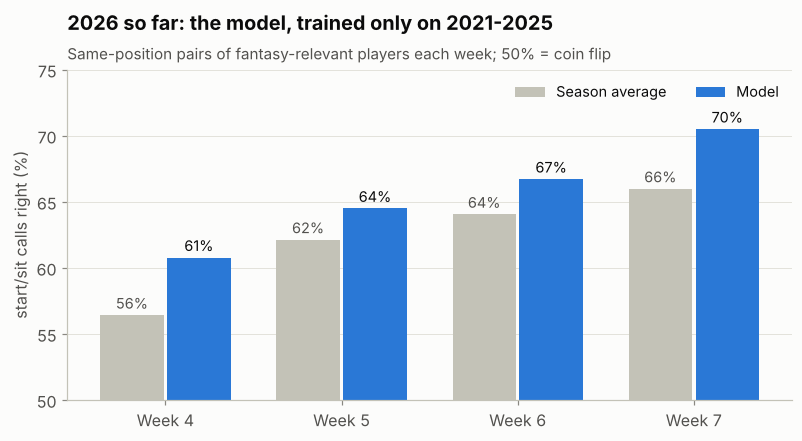

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 3.9))
wk = by_week.drop("All")
x = np.arange(len(wk))
w = 0.36
ax.bar(x - w / 2 - 0.01, wk["start/sit season avg"] * 100, width=w, color=P.GREY, label="Season average")
ax.bar(x + w / 2 + 0.01, wk["start/sit model"] * 100, width=w, color=P.BLUE, label="Model")
for xi, v in zip(x, wk["start/sit model"] * 100):
    ax.text(xi + w / 2 + 0.01, v + 0.5, f"{v:.0f}%", ha="center", color=P.INK, fontsize=9.5)
for xi, v in zip(x, wk["start/sit season avg"] * 100):
    ax.text(xi - w / 2 - 0.01, v + 0.5, f"{v:.0f}%", ha="center", color=P.INK_2, fontsize=9.5)
ax.set_xticks(x, [f"Week {int(i)}" for i in wk.index])
ax.set_ylim(50, 75)
ax.grid(axis="x", visible=False)
ax.set_ylabel("start/sit calls right (%)")
ax.legend(loc="upper right", fontsize=9.5, ncols=2)
ax.set_title("2026 so far: the model, trained only on 2021-2025", pad=26)
P.subtitle(ax, "Same-position pairs of fantasy-relevant players each week; 50% = coin flip")
P.save(fig, "16_2026_backtest")

## Week 8

Retrained on everything through week 7 of 2026 (the current season's games are fair game now). Notes:

* **Injury reports** for week 8 come out Wednesday through Friday. Until then everyone is treated as untagged; rerun the
  script Friday afternoon for tag-adjusted numbers.
* `no_line`: the game had no Vegas line yet, so the week's average team total is used.
* Players who missed their team's last game (injured, benched) aren't projected.

In [4]:
live_model = fit(played)
proj = project_week(df, live_model, SEASON, WEEK)
print(f"{len(proj)} players projected; {int(proj.no_line.sum())} in games without a line yet; "
      f"{int((proj.injury != '').sum())} with an injury tag")
proj.to_csv(f"../reports/projections/{SEASON}_week{WEEK:02d}.csv", index=False)
TOP = {"QB": 12, "RB": 24, "WR": 24, "TE": 12}
show = proj[proj.pos_rank <= proj.position.map(TOP)]
show = show.rename(columns={"player_display_name": "player", "opponent_team": "opp", "avg_season": "season avg",
                            "avg_last3": "last 3", "snap_last3": "snap % (last 3)", "def_factor": "matchup",
                            "implied_total": "team total"})

170 players projected; 25 in games without a line yet; 0 with an injury tag


In [5]:
show[show.position == "QB"].drop(columns=["position", "no_line", "injury"]).round(2)

,pos_rank,player,team,opp,projection,season avg,last 3,snap % (last 3),matchup,team total
0,1,Josh Allen,BUF,BAL,21.33,26.88,22.44,1.00,1.00,28.50
1,2,Drake Maye,NE,MIA,20.20,19.78,30.23,1.00,1.17,26.00
2,3,Trevor Lawrence,JAX,IND,19.13,19.03,20.72,1.00,1.06,27.00
3,4,Joe Burrow,CIN,TEN,18.98,21.69,25.73,0.98,0.91,28.25
4,5,Jayden Daniels,WAS,PHI,18.59,21.42,22.67,0.85,1.16,22.88
5,6,Matthew Stafford,LA,LAC,17.89,17.62,20.57,1.00,0.85,25.50
6,7,Jared Goff,DET,MIN,17.59,22.17,22.48,0.98,0.45,24.75
7,8,Caleb Williams,CHI,SEA,17.02,20.90,15.45,0.95,0.62,21.75
8,9,Jordan Love,GB,CAR,17.00,18.19,20.83,0.99,0.96,25.50
9,10,Kyler Murray,MIN,DET,16.32,10.74,14.55,1.00,1.53,21.75


In [6]:
show[show.position == "RB"].drop(columns=["position", "no_line", "injury"]).round(2)

,pos_rank,player,team,opp,projection,season avg,last 3,snap % (last 3),matchup,team total
28,1,Jahmyr Gibbs,DET,MIN,23.42,28.50,24.23,0.82,0.73,24.75
29,2,Bijan Robinson,ATL,TB,19.83,20.81,13.43,0.80,0.82,22.00
30,3,James Cook,BUF,BAL,18.47,18.93,21.13,0.62,0.84,28.50
31,4,Kenneth Walker III,KC,DEN,17.64,24.62,22.83,0.74,1.05,21.50
32,5,Chase Brown,CIN,TEN,17.02,12.47,11.97,0.71,1.01,28.25
33,6,Jonathan Taylor,IND,JAX,16.88,19.64,17.10,0.73,0.79,19.50
34,7,Ashton Jeanty,LV,NYJ,16.73,17.43,16.03,0.61,0.98,22.00
35,8,D'Andre Swift,CHI,SEA,16.62,17.54,19.77,0.67,0.95,21.75
36,9,Bucky Irving,TB,ATL,16.57,15.66,20.80,0.66,1.12,24.50
37,10,Kyren Williams,LA,LAC,16.01,19.59,15.80,0.65,1.07,25.50


In [7]:
show[show.position == "WR"].drop(columns=["position", "no_line", "injury"]).round(2)

,pos_rank,player,team,opp,projection,season avg,last 3,snap % (last 3),matchup,team total
106,1,Jaxon Smith-Njigba,SEA,CHI,20.34,28.02,26.50,0.84,0.95,24.75
107,2,Puka Nacua,LA,LAC,20.13,22.72,24.50,0.87,0.95,25.50
108,3,Zay Flowers,BAL,BUF,18.40,20.37,18.33,0.85,1.33,25.00
109,4,Amon-Ra St. Brown,DET,MIN,17.07,21.40,17.53,0.87,0.79,24.75
110,5,Tee Higgins,CIN,TEN,16.14,17.02,19.23,0.78,1.12,28.25
111,6,CeeDee Lamb,DAL,ARI,16.09,22.21,14.43,0.72,1.05,22.88
112,7,Drake London,ATL,TB,15.29,15.43,16.87,0.93,0.96,22.00
113,8,Ja'Marr Chase,CIN,TEN,15.08,16.18,14.20,0.65,1.12,28.25
114,9,George Pickens,DAL,ARI,14.11,13.93,19.00,0.88,1.05,22.88
115,10,Christian Watson,GB,CAR,13.88,18.50,17.47,0.83,0.88,25.50


In [8]:
show[show.position == "TE"].drop(columns=["position", "no_line", "injury"]).round(2)

,pos_rank,player,team,opp,projection,season avg,last 3,snap % (last 3),matchup,team total
73,1,Trey McBride,ARI,DAL,17.18,18.60,20.33,0.93,0.89,22.88
74,2,Brock Bowers,LV,NYJ,14.73,19.10,15.77,0.84,0.75,22.00
75,3,Tucker Kraft,GB,CAR,12.40,10.17,11.70,0.81,0.96,25.50
76,4,Sam LaPorta,DET,MIN,11.88,13.23,15.00,0.88,0.49,24.75
77,5,Dallas Goedert,PHI,WAS,11.83,11.36,10.57,0.75,1.55,22.88
78,6,T.J. Hockenson,MIN,DET,11.68,10.45,13.37,0.54,2.11,21.75
79,7,Brenton Strange,JAX,IND,11.68,9.98,13.23,0.81,0.98,27.00
80,8,Dalton Kincaid,BUF,BAL,11.37,10.08,5.40,0.67,0.89,28.50
81,9,Hunter Henry,NE,MIA,11.23,9.66,14.10,0.72,1.52,26.00
82,10,Travis Kelce,KC,DEN,10.51,11.72,7.07,0.77,1.14,21.50


## Where the model and the box score disagree

The model's projection minus the player's 2026 average, among starters. Seven weeks is a small sample, so the
highest averages get pulled back toward last season and toward what the player's volume usually produces: most of the
orange bars are that regression, not a bad matchup. Blue bars are players whose volume, snap share, or last season
says their 2026 average undersells them.

PosixPath('/home/user/nfl-historic-analysis/reports/figures/17_week8_gaps.png')

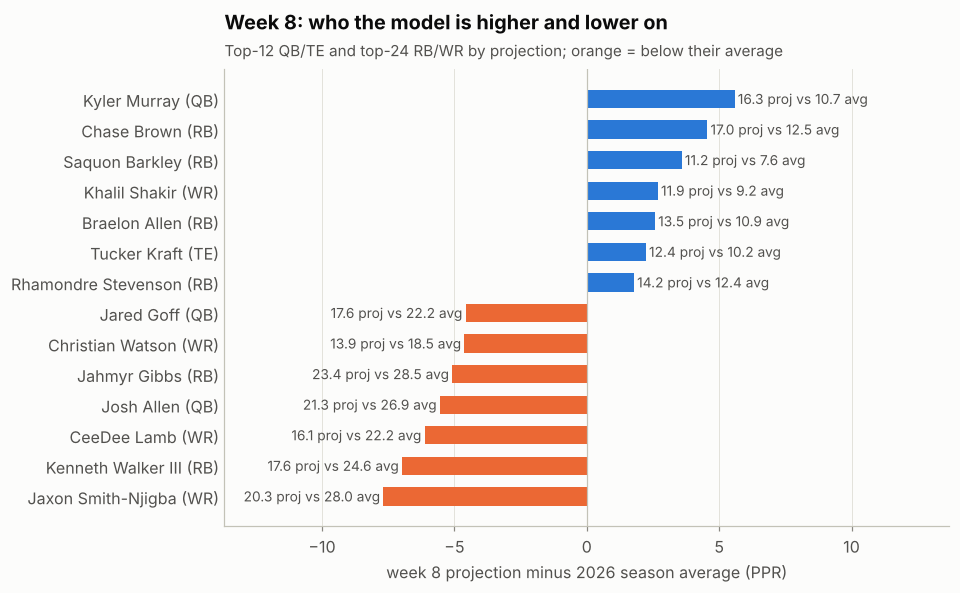

In [9]:
starters = proj[proj.pos_rank <= proj.position.map(TOP)].copy()
starters["gap"] = starters.projection - starters.avg_season
picks = pd.concat([starters.nsmallest(7, "gap"), starters.nlargest(7, "gap")]).sort_values("gap")
fig, ax = plt.subplots(figsize=(8.5, 5.4))
y = np.arange(len(picks))
ax.barh(y, picks.gap, height=0.6, color=[P.BLUE if g > 0 else P.ORANGE for g in picks.gap])
for yi, g, p, a in zip(y, picks.gap, picks.projection, picks.avg_season):
    ax.text(g + (0.12 if g > 0 else -0.12), yi, f"{p:.1f} proj vs {a:.1f} avg", va="center",
            ha="left" if g > 0 else "right", color=P.INK_2, fontsize=9)
ax.set_yticks(y, [f"{n} ({pos})" for n, pos in zip(picks.player_display_name, picks.position)])
ax.tick_params(axis="y", length=0)
ax.axvline(0, color=P.GREY, linewidth=0.8)
ax.grid(axis="y", visible=False)
lim = picks.gap.abs().max() + 6
ax.set_xlim(-lim, lim)
ax.set_xlabel("week 8 projection minus 2026 season average (PPR)")
ax.set_title("Week 8: who the model is higher and lower on", pad=26)
P.subtitle(ax, "Top-12 QB/TE and top-24 RB/WR by projection; orange = below their average")
P.save(fig, "17_week8_gaps")